# CR3BP for a binary-star system: equilibria, linear stability and simulation
**Scope.** Planar circular restricted three-body problem (CR3BP): two stars (masses $1-\mu$ and $\mu$) on circular orbits,
and a massless third body. Units: $G=1$, $m_1+m_2=1$, separation $=1$, angular velocity $n=1$ (period $2\pi$).
This notebook computes everything reported in the project report: equilibria, their dependence on $\mu$, potential contours,
linearisation, eigen-analysis, stability classification, simulations, and verification checks.
Run all cells top to bottom (about 1-2 minutes). Outputs go to `data/` and `figures/`.

### 1. LAGRANGE POINTS VS $\mu$

In [2]:
import numpy as np
import pandas as pd
from pathlib import Path
from scipy.optimize import brentq

def collinear_equation(x, mu):
    r1, r2 = abs(x + mu), abs(x - 1 + mu)
    return x - (1 - mu) * (x + mu) / r1**3 - mu * (x - 1 + mu) / r2**3b

def lagrange_points(mu):
    eps = 1e-9
    x1 = brentq(collinear_equation, -mu + eps, 1 - mu - eps, args=(mu,))
    x2 = brentq(collinear_equation, 1 - mu + eps, 1 - mu + 5, args=(mu,))
    x3 = brentq(collinear_equation, -mu - 5, -mu - eps, args=(mu,))
    x45 = 0.5 - mu
    return x1, x2, x3, x45

mu_values = np.linspace(0, 0.5, 1000)
mu_values[0] = 1e-6

y45 = f"±{np.sqrt(3) / 2:.10f}"          # "±0.8660254038"

rows = []
for mu in mu_values:
    x1, x2, x3, x45 = lagrange_points(mu)
    rows.append({
        "mu": mu,
        "L1_x": x1,
        "L2_x": x2,
        "L3_x": x3,
        "L4_L5_x": x45,
        "L4_L5_y": y45,                  # L4 = +, L5 = -
    })

df = pd.DataFrame(rows)

out_dir = Path("data")
out_dir.mkdir(parents=True, exist_ok=True)
out_path = out_dir / "lagrange_points.csv"
df.to_csv(out_path, index=False, float_format="%.10f", encoding="utf-8-sig")

print(f"Saved to {out_path.resolve()}")
df.head()

Saved to C:\Users\SOUL\Documents\GITHUB\CR3BP_model-simulation\data\lagrange_points.csv


,mu,L1_x,L2_x,L3_x,L4_L5_x,L4_L5_y
0,0.000001,0.993081,1.006949,-1.000000,0.499999,±0.8660254038
1,0.000501,0.945471,1.055547,-1.000209,0.499499,±0.8660254038
2,0.001001,0.931264,1.069939,-1.000417,0.498999,±0.8660254038
3,0.001502,0.921231,1.079966,-1.000626,0.498498,±0.8660254038
4,0.002002,0.913189,1.087893,-1.000834,0.497998,±0.8660254038


### 2. Potential Contours 

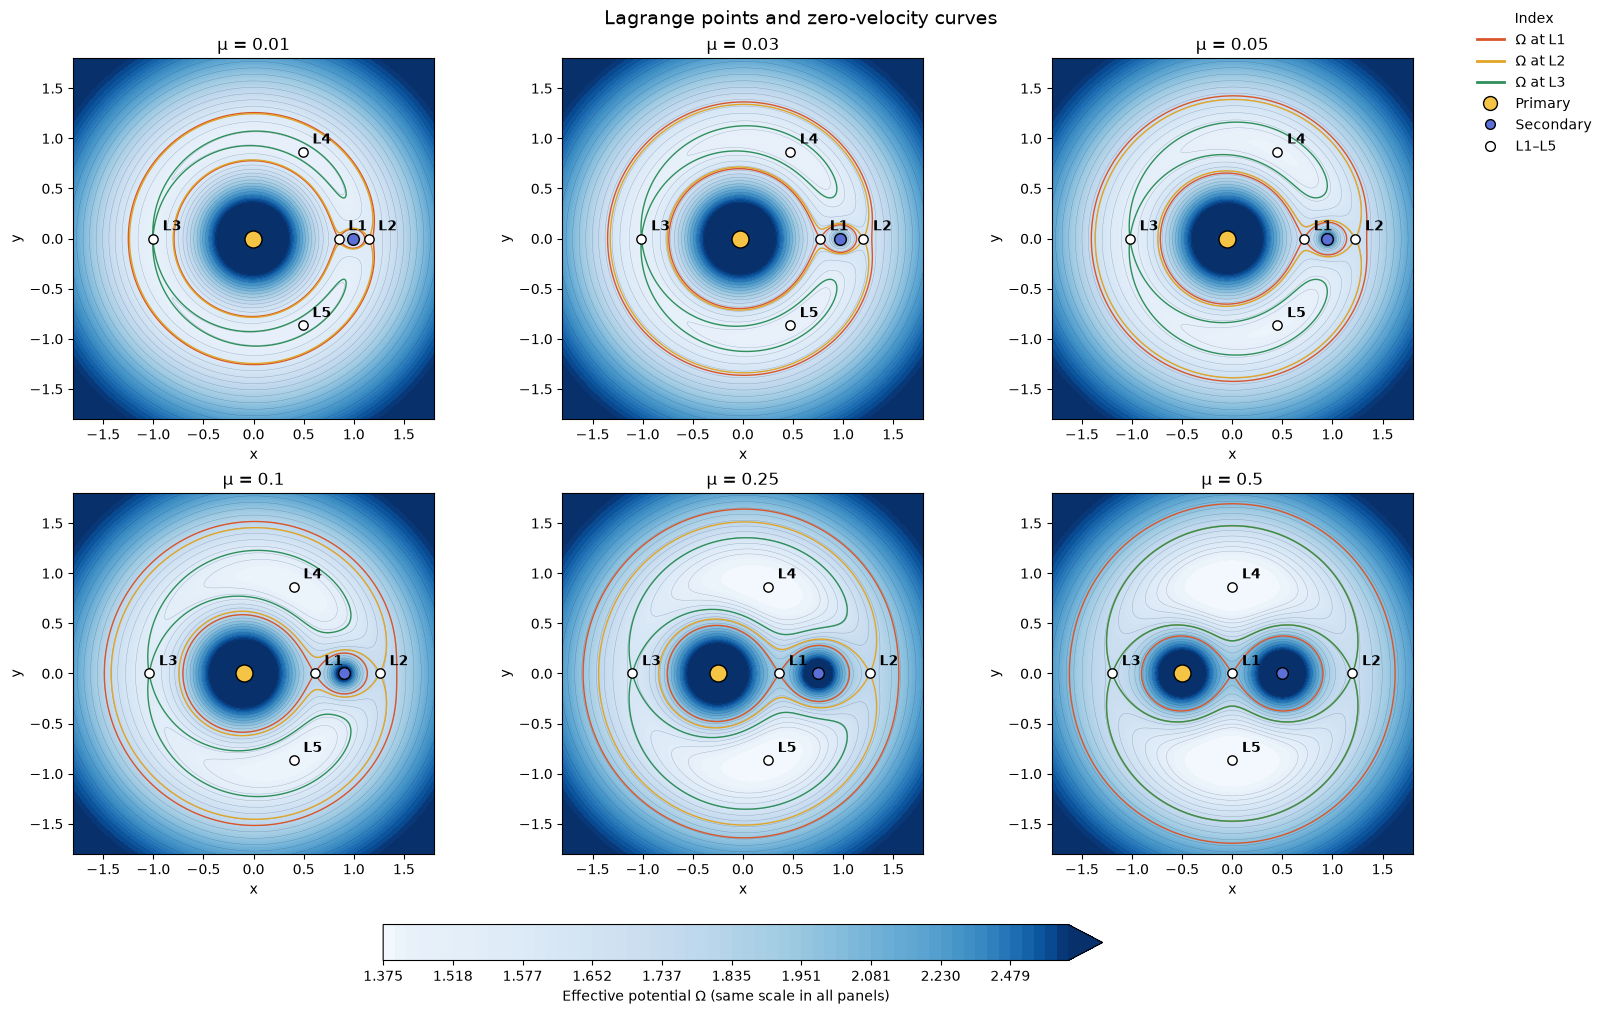

['figure1_all.png']


In [9]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path
from scipy.optimize import brentq

def distances(x, y, mu):
    return np.hypot(x + mu, y), np.hypot(x - 1 + mu, y)

def omega(x, y, mu):
    r1, r2 = distances(x, y, mu)
    return 0.5 * (x**2 + y**2) + (1 - mu) / r1 + mu / r2

def collinear_equation(x, mu):
    r1, r2 = abs(x + mu), abs(x - 1 + mu)
    return x - (1 - mu) * (x + mu) / r1**3 - mu * (x - 1 + mu) / r2**3

def lagrange_points(mu):
    eps = 1e-9
    x1 = brentq(collinear_equation, -mu + eps, 1 - mu - eps, args=(mu,))
    x2 = brentq(collinear_equation, 1 - mu + eps, 1 - mu + 5, args=(mu,))
    x3 = brentq(collinear_equation, -mu - 5, -mu - eps, args=(mu,))
    return np.array([[x1, 0], [x2, 0], [x3, 0],
                     [0.5 - mu, np.sqrt(3) / 2],
                     [0.5 - mu, -np.sqrt(3) / 2]])

def potential_grid(mu, limit=1.8):
    axis = np.linspace(-limit, limit, 1000)
    x, y = np.meshgrid(axis, axis)
    r1, r2 = distances(x, y, mu)
    U = omega(x, y, mu)
    U[(r1 < 0.02) | (r2 < 0.02)] = np.nan
    return x, y, U

def shared_levels(mu_list, limit=1.8):
    """One set of colour levels computed from all mu values together."""
    pooled = np.concatenate([potential_grid(m, limit)[2].ravel() for m in mu_list])
    return np.quantile(pooled[np.isfinite(pooled)], np.linspace(0.0, 0.93, 60))

def plot_lagrange_points(mu, limit=1.8, levels=None, ax=None, save_to=None):
    pts = lagrange_points(mu)
    x, y, U = potential_grid(mu, limit)

    # Potential field: white (low) -> deep blue (high)
    if levels is None:                       # original behaviour: per-plot levels
        levels = np.quantile(U[np.isfinite(U)], np.linspace(0.0, 0.93, 60))

    standalone = ax is None
    if standalone:
        fig, ax = plt.subplots(figsize=(10, 7), constrained_layout=True)

    cf = ax.contourf(x, y, U, levels=levels, cmap="Blues", extend="max")
    ax.contour(x, y, U, levels=levels[::4], colors="#1f3a5f",
               linewidths=0.3, alpha=0.35)

    # Critical zero-velocity curves: Ω equal to its value at L1, L2, L3
    crit = [
        (omega(*pts[0], mu), "#d9552b", "Ω at L1"),
        (omega(*pts[1], mu), "#e0a526", "Ω at L2"),
        (omega(*pts[2], mu), "#2f8f5b", "Ω at L3"),
    ]
    handles = []
    for level, colour, name in crit:
        ax.contour(x, y, U, levels=[level], colors=colour, linewidths=1)
        handles.append(Line2D([], [], color=colour, lw=1,
                              label=f"{name}  ({level:.4f})"))

    # Primaries
    ax.scatter(-mu, 0, c="#f6c445", s=150, edgecolor="k", zorder=5)
    ax.scatter(1 - mu, 0, c="#5b6fd6", s=70, edgecolor="k", zorder=5)
    handles += [
        Line2D([], [], marker="o", ls="", mfc="#f6c445", mec="k",
               ms=10, label="Primary"),
        Line2D([], [], marker="o", ls="", mfc="#5b6fd6", mec="k",
               ms=7, label="Secondary"),
    ]

    # Lagrange points
    for i, (px, py) in enumerate(pts, start=1):
        ax.scatter(px, py, c="white", s=45, edgecolor="k", zorder=6)
        ax.annotate(f"L{i}", (px, py), xytext=(7, 6),
                    textcoords="offset points", fontsize=10, fontweight="bold")
        handles.append(Line2D([], [], marker="o", ls="", mfc="white",
                              mec="k", ms=7,
                              label=f"L{i}  ({px:+.4f}, {py:+.4f})"))

    ax.set_xlim(-limit, limit)
    ax.set_ylim(-limit, limit)
    ax.set_aspect("equal")
    ax.set_xlabel("x")
    ax.set_ylabel("y")

    if standalone:
        ax.set_title(f"Lagrange points and zero-velocity curves, μ = {mu}")
        fig.colorbar(cf, ax=ax, location="bottom", shrink=0.7, pad=0.03,
                     label="Effective potential Ω")
        ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.02, 1),
                  frameon=False, fontsize=9, title="Index")
        if save_to:
            fig.savefig(save_to, dpi=300)
        plt.close(fig)
    else:
        ax.set_title(f"μ = {mu}")
    return cf

# ---------------- run for six mu values ----------------
mu_list = [0.01, 0.03, 0.05, 0.10, 0.25, 0.50]
out_dir = Path("figures")
out_dir.mkdir(parents=True, exist_ok=True)

levels = shared_levels(mu_list)          # one common colour scale

# one combined PNG, one colorbar
fig, axes = plt.subplots(2, 3, figsize=(16, 10), constrained_layout=True)
for ax, mu in zip(axes.ravel(), mu_list):
    cf = plot_lagrange_points(mu, levels=levels, ax=ax)

fig.colorbar(cf, ax=axes, location="bottom", shrink=0.5, pad=0.03,
             label="Effective potential Ω (same scale in all panels)")

shared = [Line2D([], [], color=c, lw=2, label=f"Ω at L{i+1}")
          for i, c in enumerate(["#d9552b", "#e0a526", "#2f8f5b"])]
shared += [
    Line2D([], [], marker="o", ls="", mfc="#f6c445", mec="k", ms=10, label="Primary"),
    Line2D([], [], marker="o", ls="", mfc="#5b6fd6", mec="k", ms=7, label="Secondary"),
    Line2D([], [], marker="o", ls="", mfc="white", mec="k", ms=7, label="L1–L5"),
]
fig.legend(handles=shared, loc="outside right upper", frameon=False,
           fontsize=10, title="Index")
fig.suptitle("Lagrange points and zero-velocity curves", fontsize=14)
fig.savefig(out_dir / "figure1_all.png", dpi=300)
plt.show()

print(sorted(p.name for p in out_dir.glob("*.png")))